# 🎨 QR Code Custom Generator

Genera códigos QR personalizados con módulos redondeados, logo centrado y título descriptivo.

**Instrucciones:** Editá únicamente la celda de configuración y ejecutá todo el notebook.

---
## ⚙️ Configuración (editá solo aquí)

In [ ]:
# ╔══════════════════════════════════════════════════════════════╗
# ║  CONFIGURACIÓN ÚNICA — Editá estos valores para tu QR      ║
# ╚══════════════════════════════════════════════════════════════╝

# Contenido del QR (URL, texto, WiFi, etc.)
QR_DATA = "https://forms.gle/FcAXW96eQFXdX1uB8"

# Título que aparece encima del QR
QR_TITLE = "Form "

# Logo centrado (ruta al archivo PNG/JPG, o None para sin logo)
LOGO_PATH = "trompo.png" # Ejemplo: "logo.png"

# Archivo de salida
OUTPUT_FILE = "qr_form.png"

# Colores (RGB)
FRONT_COLOR = (32, 134, 4)       # Color de los módulos/dots
BACK_COLOR = (255, 255, 255)     # Color de fondo

# Estilo de redondeo (0.0 = cuadrado, 1.0 = círculo completo)
MODULE_RADIUS = 1.0   # Redondeo de los módulos internos
EYE_RADIUS = 0.7      # Redondeo de los ojos/esquinas

# Tamaño
BOX_SIZE = 20          # Píxeles por módulo
BORDER_MODULES = 2     # Módulos de borde silencioso

---
## 📦 Imports

In [18]:
"""Dependencies for QR generation."""

from pathlib import Path
from typing import Optional

import qrcode
from qrcode.image.styledpil import StyledPilImage
from qrcode.image.styles.moduledrawers.pil import RoundedModuleDrawer
from qrcode.image.styles.colormasks import SolidFillColorMask
from PIL import Image, ImageDraw, ImageFont

print("✅ Imports OK")

✅ Imports OK


---
## 🔧 Funciones internas

In [19]:
def _embed_logo(qr_image: Image.Image, logo_path: Path) -> Image.Image:
    """Place a logo in the center of the QR code with a white circular background.

    Args:
        qr_image: The QR code as a PIL RGBA image.
        logo_path: Path to the logo file.

    Returns:
        QR image with the logo embedded in the center.
    """
    logo_raw = Image.open(logo_path).convert("RGBA")

    # Logo occupies ~22% of QR width for safe readability
    qr_width = qr_image.size[0]
    logo_max_size = int(qr_width * 0.22)
    logo_raw.thumbnail((logo_max_size, logo_max_size), Image.LANCZOS)

    # Create circular white background behind logo
    padding = 15
    bg_diameter = max(logo_raw.size) + padding * 2
    logo_background = Image.new("RGBA", (bg_diameter, bg_diameter), (0, 0, 0, 0))
    bg_draw = ImageDraw.Draw(logo_background)
    bg_draw.ellipse(
        [0, 0, bg_diameter - 1, bg_diameter - 1],
        fill=(255, 255, 255, 255),
    )

    # Paste logo centered on the white circle
    logo_offset_x = (bg_diameter - logo_raw.size[0]) // 2
    logo_offset_y = (bg_diameter - logo_raw.size[1]) // 2
    logo_background.paste(logo_raw, (logo_offset_x, logo_offset_y), logo_raw)

    # Paste circle+logo centered on QR
    center_x = (qr_image.size[0] - bg_diameter) // 2
    center_y = (qr_image.size[1] - bg_diameter) // 2
    qr_image.paste(logo_background, (center_x, center_y), logo_background)

    return qr_image

In [20]:
def _add_title(qr_image: Image.Image, title: str) -> Image.Image:
    """Add a title above the QR code on a clean white canvas.

    Args:
        qr_image: The QR code image (with or without logo).
        title: Text to display above the QR code.

    Returns:
        Final composed image with title and QR.
    """
    qr_width, qr_height = qr_image.size

    # Determine font size relative to QR width
    font_size = max(24, qr_width // 18)
    try:
        font = ImageFont.truetype("arial.ttf", font_size)
    except OSError:
        try:
            font = ImageFont.truetype("/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf", font_size)
        except OSError:
            font = ImageFont.load_default()

    # Calculate text dimensions
    dummy_draw = ImageDraw.Draw(Image.new("RGBA", (1, 1)))
    text_bbox = dummy_draw.textbbox((0, 0), title, font=font)
    text_width = text_bbox[2] - text_bbox[0]
    text_height = text_bbox[3] - text_bbox[1]

    # Canvas dimensions
    margin_top = 30
    margin_bottom = 20
    spacing = 15
    canvas_width = max(qr_width, text_width + 40)
    canvas_height = margin_top + text_height + spacing + qr_height + margin_bottom

    # Draw final canvas
    canvas = Image.new("RGBA", (canvas_width, canvas_height), (255, 255, 255, 255))
    draw = ImageDraw.Draw(canvas)

    # Title centered horizontally
    title_x = (canvas_width - text_width) // 2
    title_y = margin_top
    draw.text((title_x, title_y), title, fill=(30, 30, 30), font=font)

    # QR centered below title
    qr_x = (canvas_width - qr_width) // 2
    qr_y = margin_top + text_height + spacing
    canvas.paste(qr_image, (qr_x, qr_y), qr_image)

    return canvas.convert("RGB")

---
## 🚀 Generación del QR

In [21]:
# --- Build QR with rounded modules ---
qr_builder = qrcode.QRCode(
    version=None,
    error_correction=qrcode.constants.ERROR_CORRECT_H,
    box_size=BOX_SIZE,
    border=BORDER_MODULES,
)
qr_builder.add_data(QR_DATA)
qr_builder.make(fit=True)

qr_image = qr_builder.make_image(
    image_factory=StyledPilImage,
    module_drawer=RoundedModuleDrawer(radius_ratio=MODULE_RADIUS),
    eye_drawer=RoundedModuleDrawer(radius_ratio=EYE_RADIUS),
    color_mask=SolidFillColorMask(
        back_color=BACK_COLOR,
        front_color=FRONT_COLOR,
    ),
)
qr_pil = qr_image.convert("RGBA")

print(f"✅ QR generado: {qr_pil.size[0]}x{qr_pil.size[1]}px")
print(f"   Contenido: {QR_DATA[:60]}{'...' if len(QR_DATA) > 60 else ''}")

✅ QR generado: 820x820px
   Contenido: https://forms.gle/FcAXW96eQFXdX1uB8


In [22]:
# --- Embed logo if configured ---
if LOGO_PATH and Path(LOGO_PATH).exists():
    qr_pil = _embed_logo(qr_pil, Path(LOGO_PATH))
    print(f"✅ Logo incrustado: {LOGO_PATH}")
elif LOGO_PATH:
    print(f"⚠️  Logo no encontrado: {LOGO_PATH} — se genera sin logo")
else:
    print("ℹ️  Sin logo (LOGO_PATH = None)")

✅ Logo incrustado: trompo.png


In [23]:
# --- Add title and compose final image ---
final_image = _add_title(qr_pil, QR_TITLE)

# Save to disk
output_path = Path(OUTPUT_FILE)
final_image.save(output_path, quality=95)
print(f"✅ Guardado en: {output_path.resolve()}")
print(f"   Tamaño final: {final_image.size[0]}x{final_image.size[1]}px")

✅ Guardado en: C:\Users\Fredy\Documents\KIRO\Neon\projects\qr_generador\qr_form.png
   Tamaño final: 820x917px


---
## 👁️ Preview

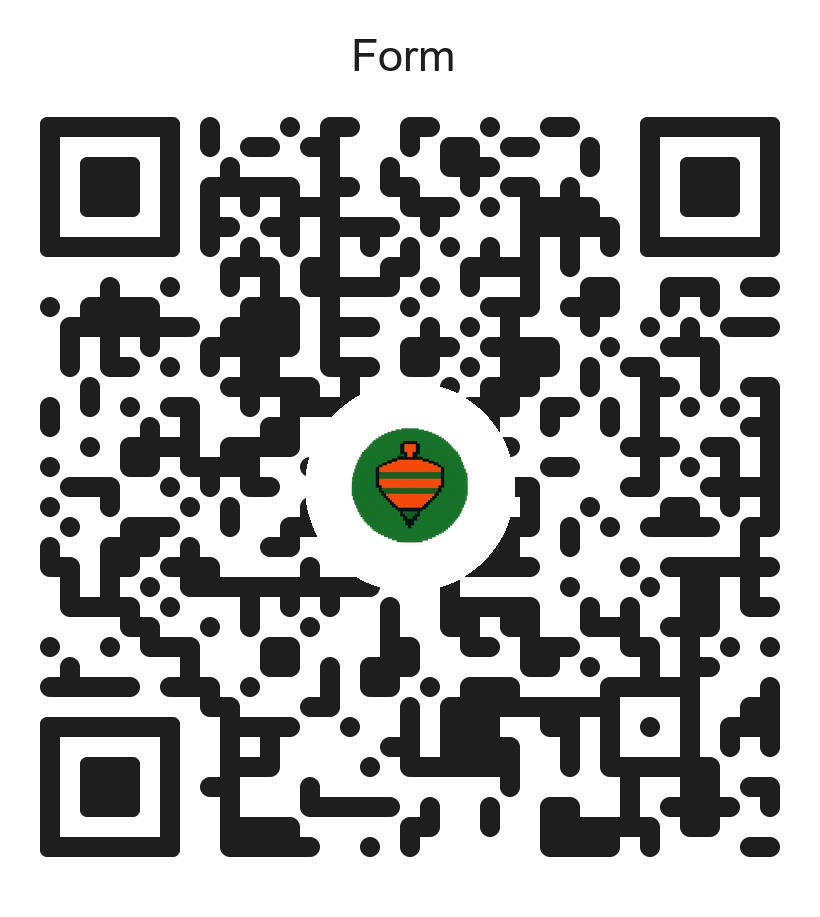

In [24]:
final_image

---
## 📝 Notas

| Parámetro | Efecto |
|-----------|--------|
| `MODULE_RADIUS = 1.0` | Módulos completamente circulares |
| `MODULE_RADIUS = 0.5` | Esquinas suavizadas (cuadrado redondeado) |
| `MODULE_RADIUS = 0.0` | Cuadrados clásicos |
| `EYE_RADIUS = 0.7` | Ojos redondeados sin perder identidad |
| `ERROR_CORRECT_H` | 30% corrección — necesario si usás logo |

**Tips:**
- El logo no debe superar ~25% del área del QR.
- Probá siempre el QR con un lector antes de distribuirlo.
- Para WiFi usá formato: `WIFI:T:WPA;S:NombreRed;P:clave;;`